# **1. Perkenalan Dataset**


Dataset ini berisi rekam medis pasien yang dikumpulkan untuk memprediksi keberadaan penyakit jantung (Heart Disease). Dataset ini terdiri dari 303 baris data dan 14 kolom (13 fitur klinis dan 1 variabel target).

### Deskripsi Kolom:
1. `age`: Umur pasien dalam tahun.
2. `sex`: Jenis kelamin (1 = laki-laki; 0 = perempuan).
3. `cp`: Tipe nyeri dada (chest pain type) (0 = asymptomatic, 1 = atypical angina, 2 = non-anginal pain, 3 = typical angina).
4. `trestbps`: Tekanan darah saat istirahat (resting blood pressure) dalam mm Hg.
5. `chol`: Kolesterol serum dalam mg/dl.
6. `fbs`: Gula darah puasa (fasting blood sugar) > 120 mg/dl (1 = true; 0 = false).
7. `restecg`: Hasil elektrokardiografi saat istirahat (0 = hypertrophy, 1 = normal, 2 = ST-T wave abnormality).
8. `thalach`: Detak jantung maksimum yang dicapai (maximum heart rate achieved).
9. `exang`: Angina yang diinduksi oleh latihan (exercise induced angina) (1 = yes; 0 = no).
10. `oldpeak`: Depresi ST yang diinduksi oleh latihan relatif terhadap istirahat.
11. `slope`: Kemiringan segmen ST latihan puncak (peak exercise ST segment slope) (0 = downsloping, 1 = flat, 2 = upsloping).
12. `ca`: Jumlah pembuluh darah utama (0-4) yang diwarnai oleh fluoroskopi.
13. `thal`: Status thalasemia (0 = null, 1 = fixed defect, 2 = normal, 3 = reversable defect).
14. `target`: Keberadaan penyakit jantung (1 = ya, 0 = tidak).


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [ ]:
#Type your code here

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Library berhasil diimpor!")

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [ ]:
#Type your code here
# Memuat data ke dalam Pandas DataFrame
df = pd.read_csv('heart-disease.csv')

# Menampilkan 5 baris pertama dataset
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [ ]:
#Type your code here
# Menampilkan informasi ringkas dataset
print("--- Informasi Dataset ---")
df.info()

# Menampilkan dimensi dataset
print(f"\nDimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Dimensi Dataset: 303 baris, 14 kolom


In [ ]:
# Memeriksa nilai kosong (missing values)
print("--- Jumlah Nilai Kosong per Kolom ---")
print(df.isna().sum())

--- Jumlah Nilai Kosong per Kolom ---
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
duplicate_count = df.duplicated().sum()
print(f"Jumlah data duplikat: {duplicate_count}")

if duplicate_count > 0:
    print("Baris yang duplikat:")
    print(df[df.duplicated()])

Jumlah data duplikat: 1
Baris yang duplikat:
     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
164   38    1   2       138   175    0        1      173      0      0.0   

     slope  ca  thal  target  
164      2   4     2       1  


In [ ]:
print("--- Deskripsi Statistik ---")
df.describe()

--- Deskripsi Statistik ---


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


/tmp/ipykernel_1285/2610192133.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2')


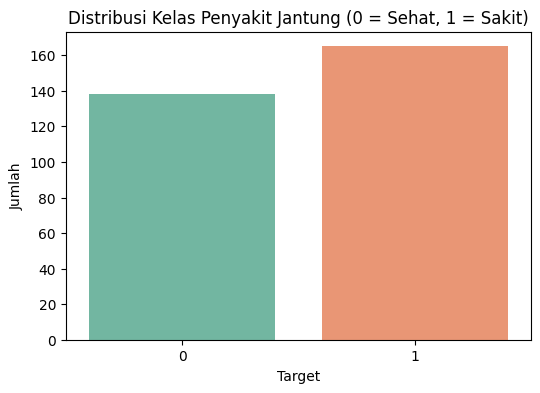

Distribusi target:
target
1    165
0    138
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='Set2')
plt.title('Distribusi Kelas Penyakit Jantung (0 = Sehat, 1 = Sakit)')
plt.xlabel('Target')
plt.ylabel('Jumlah')
plt.show()

print("Distribusi target:")
print(df['target'].value_counts())

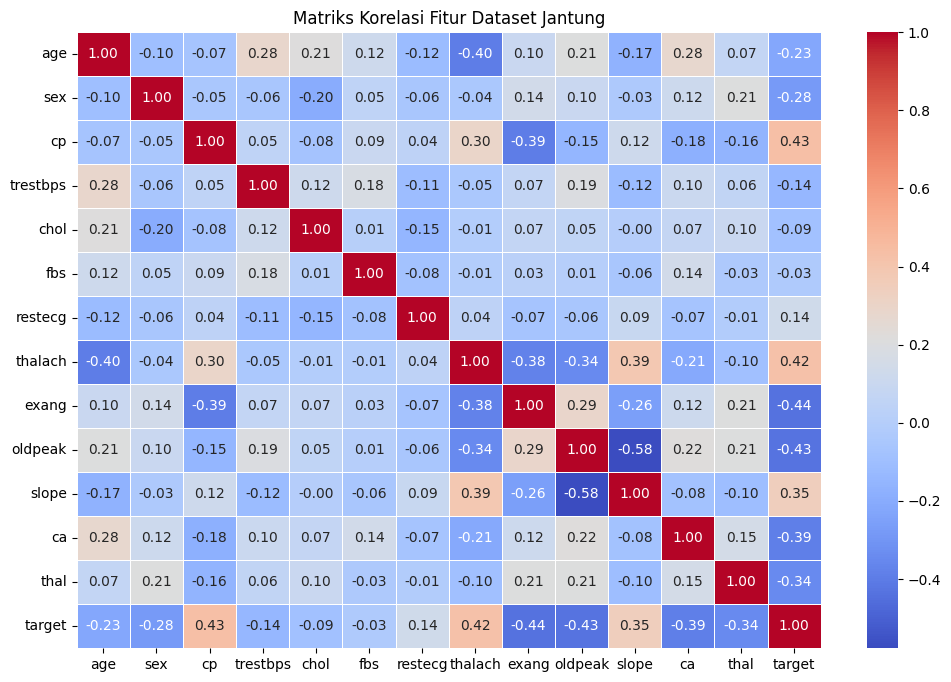

In [ ]:
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Fitur Dataset Jantung')
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [ ]:
# 1. Menghapus data duplikat
if df.duplicated().sum() > 0:
    df = df.drop_duplicates()
    print(f"Data duplikat telah dihapus. Dimensi baru: {df.shape}")
else:
    print("Tidak ada data duplikat yang perlu dihapus.")

Data duplikat telah dihapus. Dimensi baru: (302, 14)


In [ ]:
X = df.drop('target', axis=1)
y = df['target']

print(f"Dimensi Fitur X: {X.shape}")
print(f"Dimensi Target y: {y.shape}")

Dimensi Fitur X: (302, 13)
Dimensi Target y: (302,)


In [ ]:
continuous_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
scaler = StandardScaler()

X_scaled = X.copy()
X_scaled[continuous_features] = scaler.fit_transform(X[continuous_features])

print("Fitur numerik telah distandarisasi!")
X_scaled.head()

Fitur numerik telah distandarisasi!


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.949794,1,3,0.764066,-0.261285,1,0,0.018826,0,1.084022,0,0,1
1,-1.928548,1,2,-0.091401,0.067741,0,1,1.636979,0,2.118926,0,0,2
2,-1.485726,0,1,-0.091401,-0.822564,0,0,0.980971,0,0.307844,2,0,2
3,0.174856,1,1,-0.661712,-0.203222,0,1,1.243374,0,-0.209608,2,0,2
4,0.285561,0,0,-0.661712,2.080602,0,1,0.587366,1,-0.382092,2,0,2


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.3,
    random_state=42,
    stratify=y)

print(f"Data Latih: {X_train.shape[0]} baris")
print(f"Data Uji: {X_test.shape[0]} baris")

Data Latih: 211 baris
Data Uji: 91 baris


In [ ]:
# 5. Menggabungkan kembali fitur dan target untuk disimpan
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)
preprocessed_df = pd.concat([X_scaled, y], axis=1)

# Folder penyimpanan di Colab
output_dir = "/content/heart-disease_preprocessing"
os.makedirs(output_dir, exist_ok=True)

# Simpan dataset
train_df.to_csv(
    f"{output_dir}/heart-disease_train.csv",
    index=False
)

test_df.to_csv(
    f"{output_dir}/heart-disease_test.csv",
    index=False
)

preprocessed_df.to_csv(
    f"{output_dir}/heart-disease_preprocessed.csv",
    index=False
)

print("File berhasil disimpan di Colab!")
print(os.listdir(output_dir))

File berhasil disimpan di Colab!
['heart-disease_preprocessed.csv', 'heart-disease_test.csv', 'heart-disease_train.csv']
